# **Blue Dart Detection**
The original darts are black and white, and blend in with the black and white fields of the board.
The darts are therefore painted blue, as the board only contains black, white, red and green.

This notebook finds a newly thrown blue dart and scores it. It uses the same board calibration, field detection and
state machine (WAITING → SETTLING → COOLDOWN) as `Board.ipynb`, and adds:

1. **Blue mask** - an HSV colour threshold finds the blue pixels on the board
2. **New blue pixels** - only the blue pixels that were not there before the throw are kept
3. **Clean mask** - opening, closing and the largest connected blob
4. **Skeleton** - the dart blob is thinned down to a one pixel wide centre line
5. **Tip** - the two ends of the skeleton are found, and the end away from the flights is the tip
6. **Score** - the tip is looked up in the field map with `field_at`

The functions live in `src/blue_darts.py`.

# **Settings**

In [1]:
from pathlib import Path
from collections import deque

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from src.Board import DartBoard
from src.scoring import field_at
from src.visualization import show, draw_fields
from src.dart_detection import calculate_difference
from src.blue_darts import (ellipse_mask, blue_mask, new_blue, clean_mask, largest_blob, skeletonize,
                            skeleton_ends, two_furthest_ends, change_mask, choose_tip, extend_tip,
                            find_dart, draw_dart, BLUE_HUE, MIN_SATURATION, MIN_VALUE)

plt.rcParams["figure.dpi"] = 72   # keeps the notebook file small

%load_ext autoreload
%autoreload 2

In [2]:
DART_VIDEO_DIR = Path("../data/dart_videos")
FIGURE_DIR = Path("../reports/figures/Implementation/Blue Darts")
SAVE_FIGURE = False
PLAY_VIDEOS = True          # set to False to skip the video players

blue_videos = sorted(DART_VIDEO_DIR.glob("blue_*.mp4"))

# The correct score of every dart, read from the file names
EXPECTED = {
    "blue_tripledart_17_4_11_32point_straightonhard": [17, 4, 11],
    "blue_tripledart_2_6_3_11point": [2, 6, 3],
    "blue_tripledart_9_bullseye_triple3_68point": [9, 50, 9],
}

# Thresholds for the state machine (same idea as Board.ipynb)
NEW_BLUE_THRESHOLD = 40       # new blue pixels needed to start a throw
STABILITY_THRESHOLD = 2.0     # mean difference to the previous frame when the board is still
STABLE_FRAMES_REQUIRED = 10   # still frames before the dart is looked for
MIN_DART_PIXELS = 40          # smallest blob that counts as a dart
TIP_EXTENSION = 5             # pixels the tip is moved past the end of the blue part
COOLDOWN_FRAMES = 10
WARMUP_FRAMES = 10

for video in blue_videos:
    print(video.name)

blue_tripledart_17_4_11_32point_straightonhard.mp4
blue_tripledart_2_6_3_11point.mp4
blue_tripledart_9_bullseye_triple3_68point.mp4


In [3]:
def save(fig, name):
    """Saves a figure for the report if SAVE_FIGURE is on."""
    if SAVE_FIGURE:
        FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURE_DIR / f"{name}.png", bbox_inches="tight", dpi=200)


def read_frames(path):
    """Reads every frame of a video into a list."""
    capture = cv2.VideoCapture(str(path))
    frames = []
    while True:
        ok, frame = capture.read()
        if not ok:
            break
        frames.append(frame)
    capture.release()
    return frames


def to_bgr(image):
    """Makes a mask or grayscale image displayable next to colour images."""
    return cv2.cvtColor(image, cv2.COLOR_GRAY2BGR) if image.ndim == 2 else image


def label(image, text):
    """Writes a text in the top left corner of a copy of the image."""
    output = to_bgr(image).copy()
    cv2.putText(output, text, (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 255), 2, cv2.LINE_AA)
    return output


def play(frames, width=900, step=2):
    """Plays a list of frames inline in the notebook (every 'step' frame)."""
    if not PLAY_VIDEOS:
        return
    handle = display(None, display_id=True)
    for frame in frames[::step]:
        scale = width / frame.shape[1]
        small = cv2.resize(frame, None, fx=scale, fy=scale)
        handle.update(Image(data=cv2.imencode(".jpg", small)[1].tobytes()))


def zoom(image, centre, half=60, size=300):
    """Cuts out a square around a point and enlarges it (nearest neighbour, so pixels stay visible)."""
    x, y = int(centre[0]), int(centre[1])
    crop = image[max(y - half, 0):y + half, max(x - half, 0):x + half]
    return cv2.resize(crop, (size, size), interpolation=cv2.INTER_NEAREST)

# **Look at the Videos**
Three videos with three blue darts each. Two are filmed from the side, so the darts are seen along their length.
In `straightonhard` the camera looks straight at the board, so the darts point at the camera.

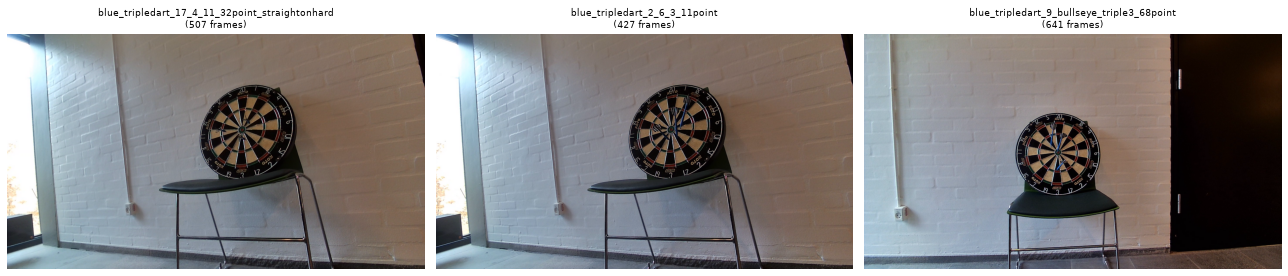

In [4]:
videos = {video.stem: read_frames(video) for video in blue_videos}

fig, axs = plt.subplots(1, 3, figsize=(18, 4))
for ax, (name, frames) in zip(axs, videos.items()):
    ax.imshow(cv2.cvtColor(frames[-1], cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}\n({len(frames)} frames)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
save(fig, "Blue_Videos")
plt.show()

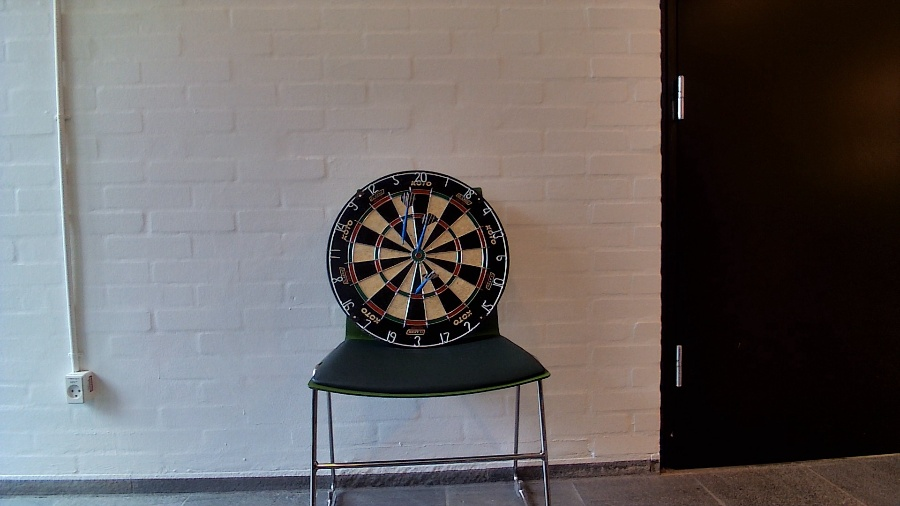

In [5]:
# Play one of the videos
EXAMPLE = "blue_tripledart_9_bullseye_triple3_68point"
play(videos[EXAMPLE])

# **Calibrate the Board**
Same functions as the other notebooks: the board is calibrated from the first frame, and the 82 fields are found.

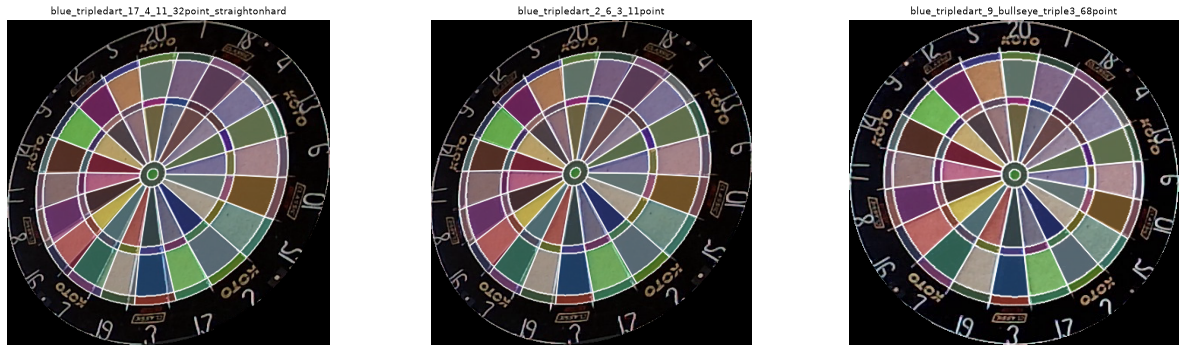

In [6]:
boards = {}
for name, frames in videos.items():
    board = DartBoard()
    board.update_frame(frames[0])
    board.calibrate(frames[0])
    board.detect_scoring_fields()
    boards[name] = board

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, board) in zip(axs, boards.items()):
    fields, _ = board.outer_drawn_fields(with_fields=True)
    ax.imshow(cv2.cvtColor(fields, cv2.COLOR_BGR2RGB))
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

# **Step 1: Blue Mask**
The image is converted to HSV:
- **Hue** is the colour itself (in OpenCV from 0 to 179: red ≈ 0, green ≈ 60, blue ≈ 120)
- **Saturation** is how strong the colour is (black, white and gray have low saturation)
- **Value** is how bright the pixel is

A pixel is called blue when its hue is in the blue range, its saturation is high enough to be a real colour,
and it is bright enough for the hue to be trusted. Very dark pixels get a random hue from noise, so they are ignored.

Hue range: (95, 130), min saturation: 80, min value: 60


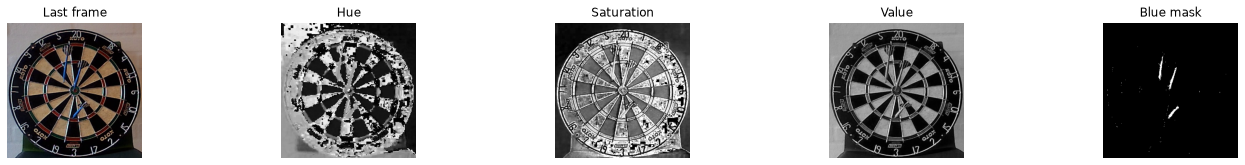

In [7]:
print(f"Hue range: {BLUE_HUE}, min saturation: {MIN_SATURATION}, min value: {MIN_VALUE}")

board = boards[EXAMPLE]
frame = videos[EXAMPLE][-1]
board_mask = ellipse_mask(frame.shape, board.outer_ellipse)
centre = board.bullseye

hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)
blue = cv2.bitwise_and(blue_mask(frame), board_mask)

half = 200
show([zoom(frame, centre, half, 400), zoom(h, centre, half, 400), zoom(s, centre, half, 400),
      zoom(v, centre, half, 400), zoom(blue, centre, half, 400)],
     ["Last frame", "Hue", "Saturation", "Value", "Blue mask"], size=4)

### **Why blue?**
The histogram shows the hue of every coloured pixel (saturation ≥ 80) on the board, before and after the darts land.
The board only has red (hue near 0 and 179) and green (near 60), so the blue darts add a peak where the board has almost nothing.

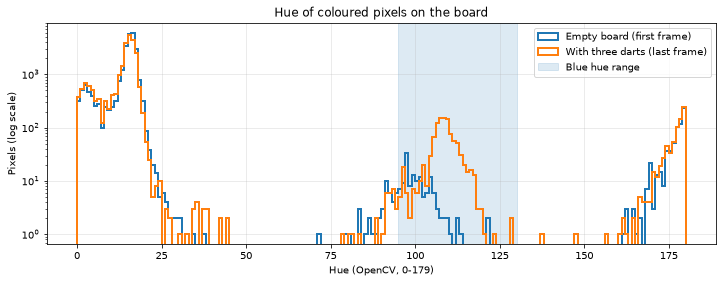

In [8]:
first = videos[EXAMPLE][0]
fig, ax = plt.subplots(figsize=(12, 4))
for image, text in [(first, "Empty board (first frame)"), (frame, "With three darts (last frame)")]:
    h_, s_, v_ = cv2.split(cv2.cvtColor(image, cv2.COLOR_BGR2HSV))
    coloured = (s_ >= MIN_SATURATION) & (v_ >= MIN_VALUE) & (board_mask > 0)
    ax.hist(h_[coloured], bins=180, range=(0, 180), histtype="step", linewidth=2, label=text)
ax.axvspan(*BLUE_HUE, color="tab:blue", alpha=0.15, label="Blue hue range")
ax.set_yscale("log")
ax.set_xlabel("Hue (OpenCV, 0-179)")
ax.set_ylabel("Pixels (log scale)")
ax.set_title("Hue of coloured pixels on the board")
ax.legend()
ax.grid(alpha=0.3)
save(fig, "Hue_Histogram")
plt.show()

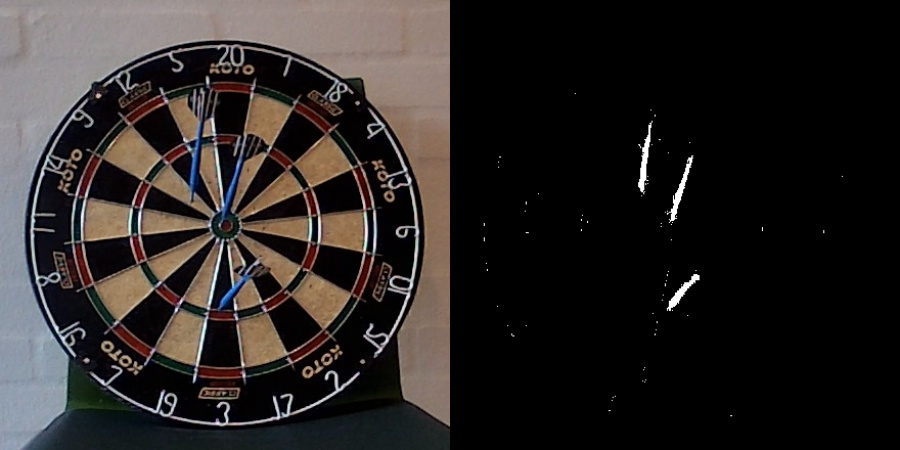

In [9]:
# Blue mask for every frame of the video (left: video, right: blue mask)
def blue_video(frames, board_mask, centre, half=220):
    output = []
    for frame in frames:
        blue = cv2.bitwise_and(blue_mask(frame), board_mask)
        output.append(np.hstack([zoom(frame, centre, half, 440), to_bgr(zoom(blue, centre, half, 440))]))
    return output

play(blue_video(videos[EXAMPLE], board_mask, centre))

# **Step 2: When is a Dart Thrown?**
`Board.ipynb` detects a throw from the mean grayscale difference to a reference frame.
On these videos a single dart only changes a small part of the board, so the change is small.
The number of blue pixels on the board instead jumps clearly every time a dart lands.

The state machine is therefore kept, but the signal is the number of **new** blue pixels compared to the reference frame.

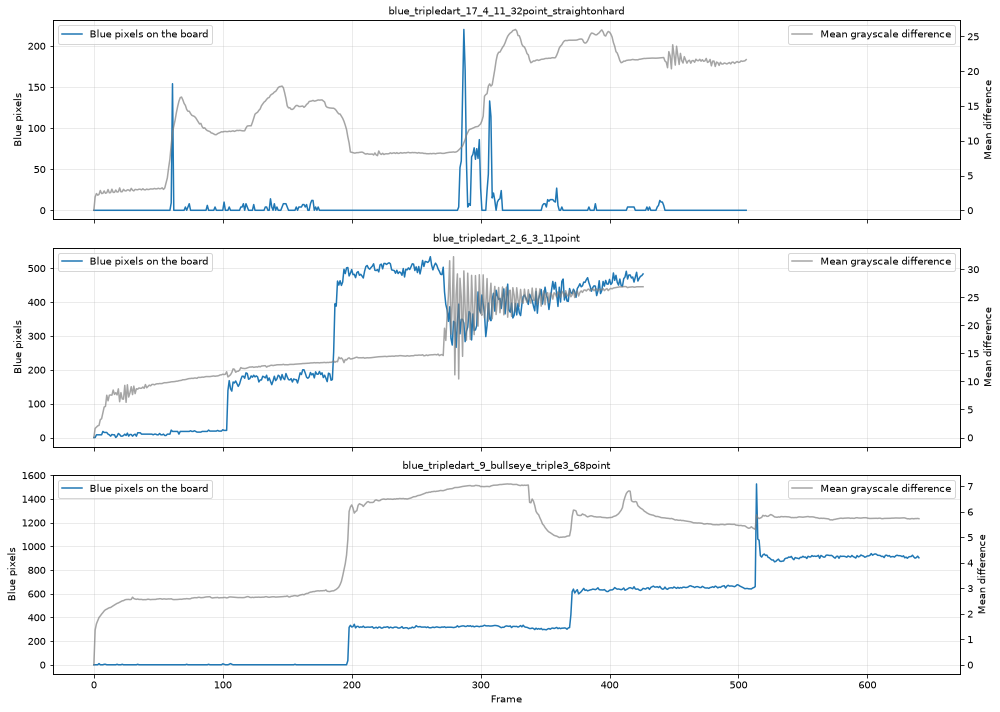

In [10]:
def signals(frames, board):
    """Mean grayscale difference to the first frame and number of blue pixels, for every frame."""
    mask = ellipse_mask(frames[0].shape, board.outer_ellipse)
    x, y, w, h = cv2.boundingRect(mask)          # crop to the board, like outer_drawn_fields
    crop = lambda image: cv2.bitwise_and(image, image, mask=mask)[y:y + h, x:x + w]
    reference = crop(frames[0])
    rows = []
    for i, frame in enumerate(frames):
        masked = crop(frame)
        difference = calculate_difference(reference, masked, i / 30)["mean_difference"]
        blue = np.count_nonzero(clean_mask(cv2.bitwise_and(blue_mask(frame), mask)))
        rows.append(dict(frame=i, mean_difference=difference, blue_pixels=blue))
    return pd.DataFrame(rows)

fig, axs = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
for ax, (name, frames) in zip(axs, videos.items()):
    data = signals(frames, boards[name])
    ax.plot(data["frame"], data["blue_pixels"], color="tab:blue", label="Blue pixels on the board")
    ax.set_ylabel("Blue pixels")
    twin = ax.twinx()
    twin.plot(data["frame"], data["mean_difference"], color="tab:gray", alpha=0.7, label="Mean grayscale difference")
    twin.set_ylabel("Mean difference")
    ax.set_title(name, fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")
    twin.legend(loc="upper right")
axs[-1].set_xlabel("Frame")
plt.tight_layout()
save(fig, "Blue_Pixels_Over_Time")
plt.show()

# **Step 3: New Blue Pixels**
To find only the newest dart, the blue mask after the throw is compared to the blue mask before the throw.
The old mask is grown a few pixels first (dilation), so that the old darts are not found again if the board moves slightly.

Below, one throw is done by hand: the frame before and after the bullseye dart.

Dart found: True, area: 316 pixels


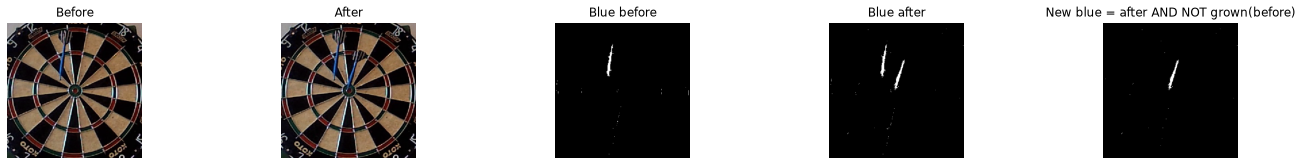

In [11]:
BEFORE, AFTER = 340, 410      # frame numbers around the second dart in the example video

before = videos[EXAMPLE][BEFORE]
after = videos[EXAMPLE][AFTER]
steps = find_dart(before, after, board_mask, MIN_DART_PIXELS, TIP_EXTENSION)
print(f"Dart found: {steps['found']}, area: {steps['area']} pixels")

show([zoom(before, centre, 150, 400), zoom(after, centre, 150, 400),
      zoom(steps["blue_before"], centre, 150, 400), zoom(steps["blue_after"], centre, 150, 400),
      zoom(steps["new_blue"], centre, 150, 400)],
     ["Before", "After", "Blue before", "Blue after", "New blue = after AND NOT grown(before)"], size=4)

# **Step 4: Clean the Mask**
- **Opening** (erosion then dilation) removes single noisy pixels
- **Closing** (dilation then erosion) fills small holes and gaps along the dart
- **Connected components** labels every separate blob, and only the largest one is kept as the dart

1 blobs, areas: [np.int32(316)]


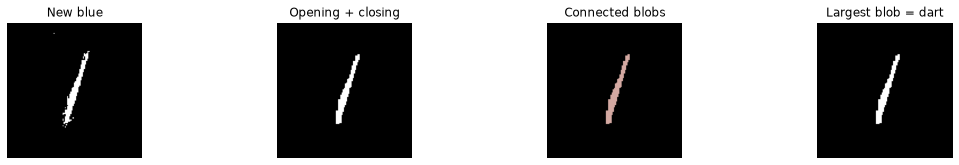

In [12]:
count, labels, stats, _ = cv2.connectedComponentsWithStats(steps["cleaned"], connectivity=8)
print(f"{count - 1} blobs, areas: {sorted(stats[1:, cv2.CC_STAT_AREA], reverse=True)}")

# Every blob in its own colour
rng = np.random.default_rng(1)
colours = np.vstack([[0, 0, 0], rng.integers(80, 255, size=(max(count - 1, 1), 3))]).astype(np.uint8)
blobs = colours[labels]

dart_centre = np.argwhere(steps["dart"] > 0).mean(axis=0)[::-1]
show([zoom(steps["new_blue"], dart_centre, 60), zoom(steps["cleaned"], dart_centre, 60),
      zoom(blobs, dart_centre, 60), zoom(steps["dart"], dart_centre, 60)],
     ["New blue", "Opening + closing", "Connected blobs", "Largest blob = dart"], size=4)

# **Step 5: Skeleton**
The dart blob is several pixels wide. Skeletonization (Zhang-Suen thinning) removes pixels from the edge of the blob,
one layer at a time, but never a pixel that would split the blob or shorten a line.
What is left is a one pixel wide centre line along the dart.

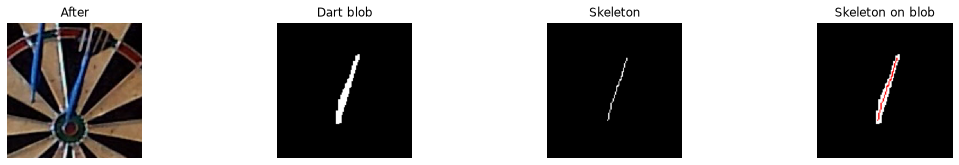

In [13]:
overlay = to_bgr(steps["dart"]).copy()
overlay[steps["skeleton"] > 0] = (0, 0, 255)

show([zoom(after, dart_centre, 60), zoom(steps["dart"], dart_centre, 60),
      zoom(steps["skeleton"], dart_centre, 60), zoom(overlay, dart_centre, 60)],
     ["After", "Dart blob", "Skeleton", "Skeleton on blob"], size=4)

# **Step 6: Which End is the Tip?**
The end points of the skeleton are the pixels with exactly one neighbour. The two end points furthest apart are the two ends of the dart.

The flights are not painted, so they are not in the blue mask, but they do change the image.
The changed pixels that are not blue are counted in a circle around each end. The end with most changes is the back (flights),
and the other end is the tip.

All skeleton end points: [[907, 482], [890, 537]]
Two furthest ends: [907, 482] and [890, 537]
Changed (non-blue) pixels near each end: (219, 0)
Back (flights): [907, 482], blue end at the tip: [890, 537]


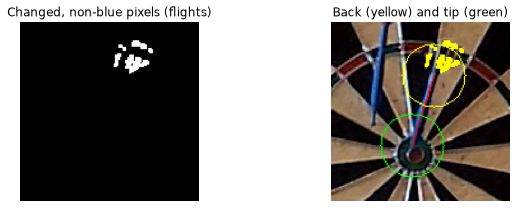

In [14]:
end_a, end_b = two_furthest_ends(steps["ends"])
print(f"All skeleton end points: {steps['ends'].tolist()}")
print(f"Two furthest ends: {end_a.tolist()} and {end_b.tolist()}")
print(f"Changed (non-blue) pixels near each end: {steps['flight_counts']}")
print(f"Back (flights): {steps['back'].tolist()}, blue end at the tip: {steps['blue_end'].tolist()}")

ends = after.copy()
ends[steps["flights"] > 0] = (0, 255, 255)
ends[steps["skeleton"] > 0] = (0, 0, 255)
for point, colour in [(steps["back"], (0, 255, 255)), (steps["blue_end"], (0, 255, 0))]:
    cv2.circle(ends, tuple(int(v) for v in point), 25, colour, 1)

show([zoom(steps["flights"], dart_centre, 70), zoom(ends, dart_centre, 70)],
     ["Changed, non-blue pixels (flights)", "Back (yellow) and tip (green)"], size=5)

# **Step 7: Score the Dart**
The steel point is not painted, and the end of the barrel is often in shadow, so the blue part stops a little before
the point where the dart enters the board. The tip is therefore moved `TIP_EXTENSION` pixels further along the dart.
The tip is then looked up in the field map.

Blue end: ('Outer bull', 25)
Tip (5 px further): ('Bull', 50)


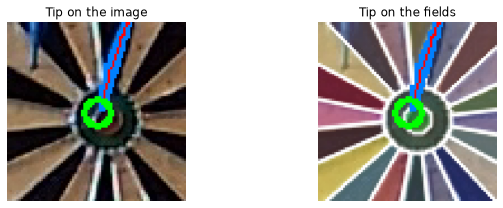

In [15]:
tip = steps["tip"]
print(f"Blue end: {field_at(*steps['blue_end'], board.fields, board.field_map)}")
print(f"Tip ({TIP_EXTENSION} px further): {field_at(*tip, board.fields, board.field_map)}")

fields_image = draw_dart(draw_fields(after, board.fields, board.field_map), steps)
show([zoom(draw_dart(after, steps), tip, 40), zoom(fields_image, tip, 40)],
     ["Tip on the image", "Tip on the fields"], size=5)

In [16]:
# How the score changes with the tip extension, for this dart
for pixels in [0, 2, 4, 6, 8, 10, 15]:
    point = extend_tip(steps["blue_end"], steps["back"], pixels)
    print(f"{pixels:3d} px: {field_at(*point, board.fields, board.field_map)}")

  0 px: ('Outer bull', 25)
  2 px: ('Bull', 50)
  4 px: ('Bull', 50)
  6 px: ('Bull', 50)
  8 px: ('Bull', 50)
 10 px: ('Bull', 50)
 15 px: ('Outer bull', 25)


# **Full Run**
The same state machine as `Board.ipynb`:
- **WAITING**: the number of new blue pixels (compared to the reference frame) is checked. Above `NEW_BLUE_THRESHOLD` a throw has started.
- **SETTLING**: waits until the board has been still for `STABLE_FRAMES_REQUIRED` frames, then the dart is found with `find_dart`.
  If no dart blob is found, the throw is a miss. The current frame becomes the new reference.
- **COOLDOWN**: waits a few frames before looking for the next throw.

The video player shows: the board with the fields and the state, the blue mask, the new blue pixels, and every dart found so far.

In [17]:
def main(name, show_video=True, step=2):
    frames = videos[name]
    board = boards[name]

    # Work on the area around the board only, like Board.ipynb
    roi, (x0, y0) = board.outer_drawn_fields(with_fields=False)
    height, width = roi.shape[:2]
    (cx, cy), axes, angle = board.outer_ellipse
    mask = ellipse_mask(roi.shape, ((cx - x0, cy - y0), axes, angle))
    fields_roi = draw_fields(frames[0], board.fields, board.field_map)[y0:y0 + height, x0:x0 + width]

    state = "WAITING"
    stable_frames = cooldown_frames = 0
    measurements, throws = [], []
    result_image = fields_roi.copy()
    handle = display(None, display_id=True) if (show_video and PLAY_VIDEOS) else None

    for frame_count, frame in enumerate(frames, 1):
        roi = frame[y0:y0 + height, x0:x0 + width]
        blue_now = cv2.bitwise_and(blue_mask(roi), mask)

        if frame_count <= WARMUP_FRAMES:
            reference, reference_blue, previous = roi.copy(), blue_now, roi.copy()
            continue

        # Signals: new blue pixels, and how much the image moved since the previous frame
        new_pixels = clean_mask(new_blue(blue_now, reference_blue))
        new_count = int(np.count_nonzero(new_pixels))
        stability = float(np.mean(cv2.absdiff(cv2.cvtColor(previous, cv2.COLOR_BGR2GRAY),
                                              cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY))))
        measurement = dict(frame=frame_count, time=frame_count / 30, new_blue=new_count, stability=stability,
                           dart_thrown=0, dart_landed=0, dart_missed=0)

        if state == "WAITING":
            if new_count > NEW_BLUE_THRESHOLD:
                state, stable_frames = "SETTLING", 0
                measurement["dart_thrown"] = 1

        elif state == "SETTLING":
            stable_frames = stable_frames + 1 if stability < STABILITY_THRESHOLD else 0

            if stable_frames >= STABLE_FRAMES_REQUIRED:
                steps = find_dart(reference, roi, mask, MIN_DART_PIXELS, TIP_EXTENSION)
                if steps["found"]:
                    tip_x, tip_y = steps["tip"]
                    field, score = field_at(tip_x + x0, tip_y + y0, board.fields, board.field_map)
                    measurement["dart_landed"] = 1
                    result_image = draw_dart(result_image, steps)
                else:
                    field, score = "Miss", 0
                    measurement["dart_missed"] = 1
                throws.append(dict(frame=frame_count, field=field, score=score, area=steps["area"],
                                   tip=None if not steps["found"] else (steps["tip"] + (x0, y0)).round(1).tolist()))
                print(f"[frame {frame_count}] Throw {len(throws)}: {field} ({score} points), dart area {steps['area']} px")

                reference, reference_blue = roi.copy(), blue_now
                state, cooldown_frames = "COOLDOWN", 0

        elif state == "COOLDOWN":
            cooldown_frames += 1
            if cooldown_frames >= COOLDOWN_FRAMES:
                state = "WAITING"

        measurement["state"] = state
        measurements.append(measurement)
        previous = roi.copy()

        if handle is not None and frame_count % step == 0:
            total = sum(t["score"] for t in throws)
            view = cv2.addWeighted(roi, 0.6, fields_roi, 0.4, 0)
            tiles = [label(view, f"{state}  throws: {len(throws)}  total: {total}"),
                     label(blue_now, f"Blue mask"),
                     label(new_pixels, f"New blue: {new_count} px"),
                     label(result_image, "Darts found")]
            tiles = [cv2.resize(t, (450, int(450 * height / width))) for t in tiles]
            grid = np.vstack([np.hstack(tiles[:2]), np.hstack(tiles[2:])])
            handle.update(Image(data=cv2.imencode(".jpg", grid)[1].tobytes()))

    print(f"Total: {sum(t['score'] for t in throws)} points from {len(throws)} throws")
    return pd.DataFrame(measurements), throws, result_image

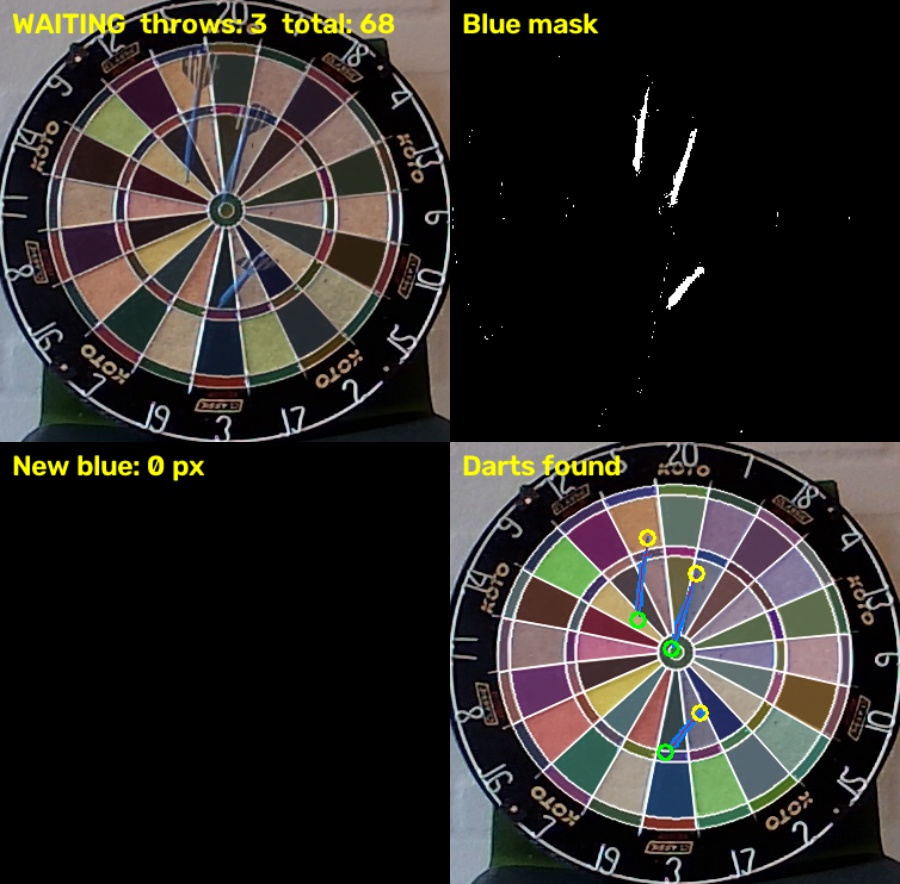

[frame 210] Throw 1: S9 inner (9 points), dart area 326 px


[frame 382] Throw 2: Bull (50 points), dart area 313 px


[frame 532] Throw 3: T3 (9 points), dart area 250 px


Total: 68 points from 3 throws


In [18]:
data, throws, result_image = main(EXAMPLE)

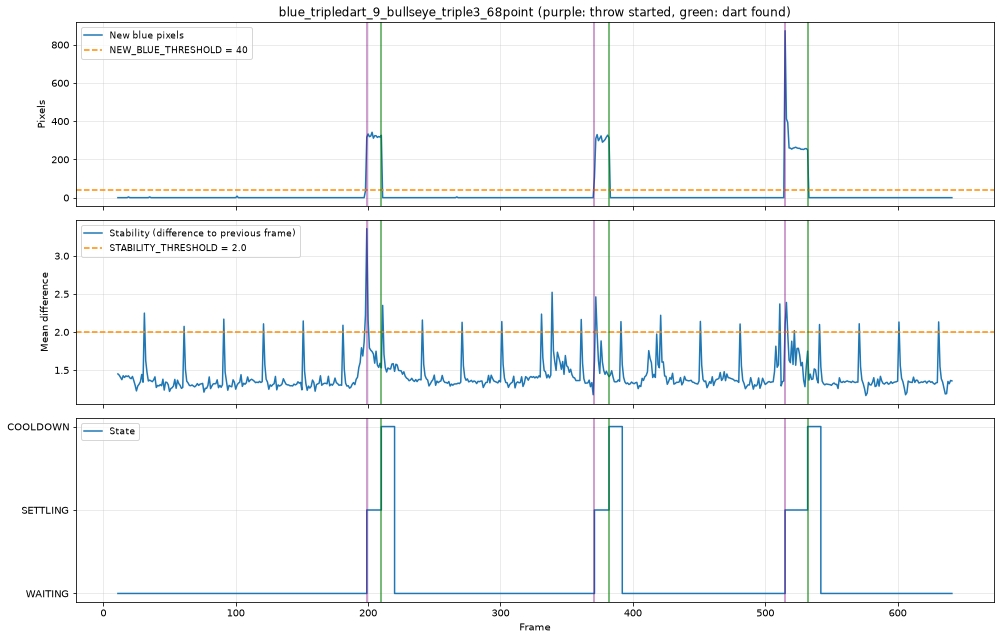

In [19]:
fig, axs = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

axs[0].plot(data["frame"], data["new_blue"], label="New blue pixels")
axs[0].axhline(NEW_BLUE_THRESHOLD, color="darkorange", linestyle="--", label=f"NEW_BLUE_THRESHOLD = {NEW_BLUE_THRESHOLD}")
axs[0].set_ylabel("Pixels")

axs[1].plot(data["frame"], data["stability"], label="Stability (difference to previous frame)")
axs[1].axhline(STABILITY_THRESHOLD, color="darkorange", linestyle="--", label=f"STABILITY_THRESHOLD = {STABILITY_THRESHOLD}")
axs[1].set_ylabel("Mean difference")

states = {"WAITING": 0, "SETTLING": 1, "COOLDOWN": 2}
axs[2].step(data["frame"], data["state"].map(states), where="post", label="State")
axs[2].set_yticks(list(states.values()), list(states.keys()))

for ax in axs:
    for frame in data.loc[data["dart_thrown"] == 1, "frame"]:
        ax.axvline(frame, color="purple", alpha=0.5)
    for frame in data.loc[data["dart_landed"] == 1, "frame"]:
        ax.axvline(frame, color="green", alpha=0.7)
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=9)
axs[0].set_title(f"{EXAMPLE} (purple: throw started, green: dart found)")
axs[-1].set_xlabel("Frame")
plt.tight_layout()
save(fig, "Blue_State_Machine")
plt.show()

# **Results on all Videos**

In [20]:
results = {}
for name in videos:
    print(f"\n{name}")
    data_, throws_, image_ = main(name, show_video=False)
    results[name] = dict(data=data_, throws=throws_, image=image_)

rows = []
for name, result in results.items():
    found = [t["score"] for t in result["throws"]]
    expected = EXPECTED[name]
    correct = sum(f == e for f, e in zip(found, expected))
    rows.append(dict(video=name, expected=expected, found=found, fields=[t["field"] for t in result["throws"]],
                     correct=f"{correct}/{len(expected)}", total_expected=sum(expected), total_found=sum(found)))
summary = pd.DataFrame(rows)
summary


blue_tripledart_17_4_11_32point_straightonhard
[frame 178] Throw 1: Miss (0 points), dart area 0 px


[frame 356] Throw 2: Miss (0 points), dart area 13 px
Total: 0 points from 2 throws

blue_tripledart_2_6_3_11point


[frame 131] Throw 1: S2 inner (2 points), dart area 158 px
[frame 206] Throw 2: S6 inner (6 points), dart area 208 px


[frame 414] Throw 3: Miss (0 points), dart area 17 px
Total: 8 points from 3 throws

blue_tripledart_9_bullseye_triple3_68point
[frame 210] Throw 1: S9 inner (9 points), dart area 326 px


[frame 382] Throw 2: Bull (50 points), dart area 313 px
[frame 532] Throw 3: T3 (9 points), dart area 250 px
Total: 68 points from 3 throws


,video,expected,found,fields,correct,total_expected,total_found
0,blue_tripledart_17_4_11_32point_straightonhard,"[17, 4, 11]","[0, 0]","[Miss, Miss]",0/3,32,0
1,blue_tripledart_2_6_3_11point,"[2, 6, 3]","[2, 6, 0]","[S2 inner, S6 inner, Miss]",2/3,11,8
2,blue_tripledart_9_bullseye_triple3_68point,"[9, 50, 9]","[9, 50, 9]","[S9 inner, Bull, T3]",3/3,68,68


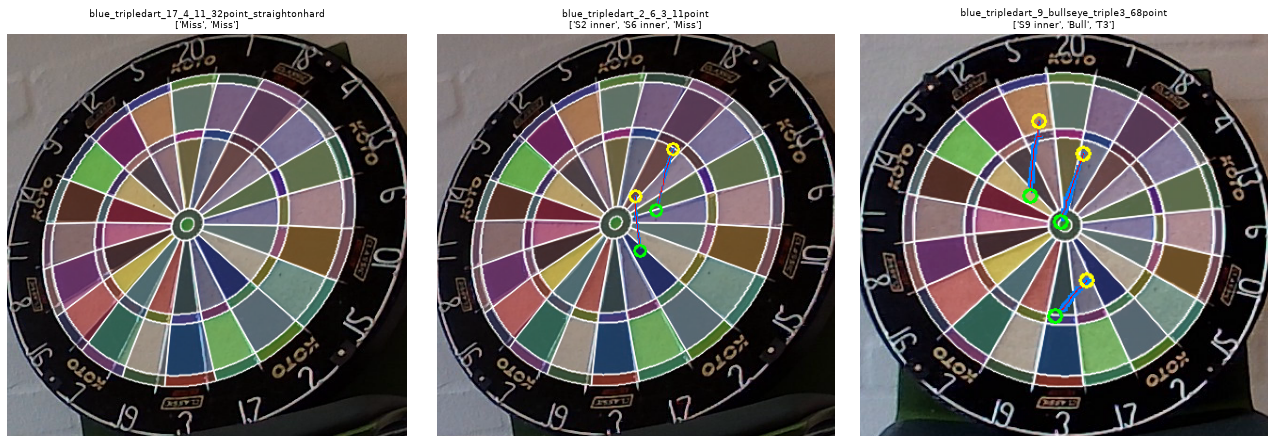

In [21]:
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, result) in zip(axs, results.items()):
    ax.imshow(cv2.cvtColor(result["image"], cv2.COLOR_BGR2RGB))
    ax.set_title(f"{name}\n{[t['field'] for t in result['throws']]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
save(fig, "Blue_Results")
plt.show()

# **Where it Fails**
**Dart in shadow:** the third dart in `blue_tripledart_2_6_3_11point` lands in the shadow of the other darts.
In the shadow it is almost black, so its hue can not be trusted and it is not in the blue mask.

**Straight on:** in `straightonhard` the darts point at the camera, so only the back of the dart is seen.
It covers around 15 pixels and is dark, so there is almost no blue to find, and the tip is hidden behind the flights.

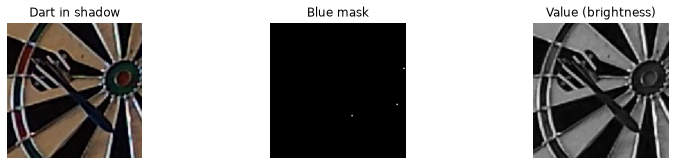

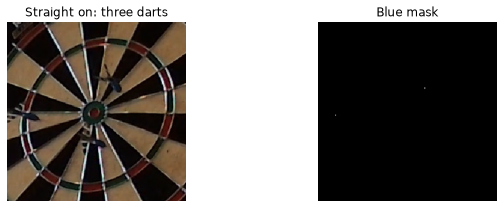

In [22]:
name = "blue_tripledart_2_6_3_11point"
last = videos[name][-1]
mask_ = ellipse_mask(last.shape, boards[name].outer_ellipse)
point = (1040, 450)    # the dart in the shadow
show([zoom(last, point, 60), zoom(cv2.bitwise_and(blue_mask(last), mask_), point, 60),
      zoom(cv2.split(cv2.cvtColor(last, cv2.COLOR_BGR2HSV))[2], point, 60)],
     ["Dart in shadow", "Blue mask", "Value (brightness)"], size=4)

name = "blue_tripledart_17_4_11_32point_straightonhard"
last = videos[name][-1]
mask_ = ellipse_mask(last.shape, boards[name].outer_ellipse)
centre_ = boards[name].bullseye
show([zoom(last, centre_, 120), zoom(cv2.bitwise_and(blue_mask(last), mask_), centre_, 120)],
     ["Straight on: three darts", "Blue mask"], size=5)